# Extra 4 - Learning without labels: autoencoders and generative models

**AI in Quantitative Biology (Univ. Milano, 2026) - supplementary notebook**

Every model in the classes was trained on labels: a toxicity, an EC class, a targeting signal. Most
biological sequences carry none. Two families of networks learn from the sequences alone:

* an **autoencoder** squeezes its input through a narrow bottleneck and learns to reproduce it; the
  bottleneck is a low-dimensional map of the data, obtained with no labels (deck p. 34);
* a **generative** sequence model learns to predict the next residue, and can then *write* new
  sequences (slides 54-56: peptides from a recurrent network, molecules from the latent space of a
  variational autoencoder).

Both parts use the class 3 data - 3600 protein N-termini labelled **SP**, **mTP** or **other**. The
labels are used only to *judge* what the networks found on their own.

| Part | Topic | Time |
|---|---|---|
| 1 | Autoencoders: a bottleneck without labels | 20 min |
| 2 | Generating peptides, and judging the result honestly | 15 min |

The models are written in PyTorch; `extra03` builds it up from scratch. Everything runs on a laptop
**CPU**. Exercises are marked ✏️ and open questions ❓; the answers follow right after.

## Setup

The cell below is collapsed on purpose: it only contains imports, the data loader and a few
helpers. Run it and move on (click the title to unfold it if you are curious).

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RNG = 0                                      # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)


def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "targeting.tsv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")


DATA_DIR = find_data_dir()
print("data from", DATA_DIR)


def load_targeting():
    """3600 protein N-termini (first 50 residues) labelled SP / mTP / other."""
    return pd.read_csv(DATA_DIR / "targeting.tsv", sep="\t")


def load_enzymes():
    """2047 enzymes with their EC class (1-6) and full sequence."""
    return pd.read_csv(DATA_DIR / "enzymes.tsv", sep="\t")


AA = "ACDEFGHIKLMNPQRSTVWY"                  # the 20 standard amino acids
AA_INDEX = {a: i for i, a in enumerate(AA)}

# Kyte-Doolittle hydropathy scale (positive = hydrophobic). Used only to *interpret* the models.
KYTE_DOOLITTLE = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5,
    "G": -0.4, "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8,
    "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2,
}
KD = np.array([KYTE_DOOLITTLE[a] for a in AA])


def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a 20-vector, sums to 1)."""
    v = np.zeros(20, dtype=np.float32)
    for a in seq:
        v[AA_INDEX[a]] += 1
    return v / max(len(seq), 1)


def one_hot(seq):
    """A length-L sequence -> an (L, 20) matrix of 0s with a single 1 per column."""
    m = np.zeros((len(seq), 20), dtype=np.float32)
    m[np.arange(len(seq)), [AA_INDEX[a] for a in seq]] = 1
    return m


colours = {"other": "tab:blue", "SP": "tab:orange", "mTP": "tab:green"}

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score


def n_params(model):
    return sum(p.numel() for p in model.parameters())


data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)
torch.set_num_threads(2)                     # keeps timings comparable between laptops
print("PyTorch", torch.__version__)

PyTorch 2.15.0


In [ ]:
tp = load_targeting()
LABELS = ["other", "SP", "mTP"]
display(tp.head(3))
print(tp["label"].value_counts().to_dict())
print(tp["nterm"].str.len().unique(), "residues per sequence")

,accession,entry_name,protein_name,organism,label,signal_len,nterm
0,A0A023PYC6,YA16A_YEAST,Putative uncharacterized membrane protein YAL0...,Saccharomyces cerevisiae,SP,25,MVSSFFMASTLLAISSCFNSSISRAKGYNDSLESESLEFDVVDVVD...
1,A0A075B6J1,LV537_HUMAN,Immunoglobulin lambda variable 5-37,Homo sapiens,SP,19,MAWTPLLLLLLSHCTGSLSQPVLTQPPSSSASPGESARLTCTLPSD...
2,A0A075B6J6,LV322_HUMAN,Immunoglobulin lambda variable 3-22,Homo sapiens,SP,20,MAWATLLLPLLNLYTGSVASYELTQLPSVSVSPGQTARITCSGDVL...


{'SP': 1200, 'mTP': 1200, 'other': 1200}
[50] residues per sequence


In [ ]:
X_all = torch.tensor(np.stack(tp["nterm"].map(one_hot)))      # (3600, 50, 20)
y_all = tp["label"].map({lab: i for i, lab in enumerate(LABELS)}).values
Y_all = torch.tensor(y_all)
print("X_all:", tuple(X_all.shape), " = proteins x positions x amino acids")
print(f"{X_all.numel():,} numbers, of which {int(X_all.sum()):,} are non-zero "
      f"({100 * X_all.mean():.0f}%)")

X_all: (3600, 50, 20)  = proteins x positions x amino acids
3,600,000 numbers, of which 180,000 are non-zero (5%)


## Part 1 - Autoencoders: a bottleneck without labels

> *"'Force' the network to cut down information by creating a 'funnel'. Input is the same as output
> (loss is reproduction error). A dimensionality reduction technique."* (deck p. 34)

Everything in the classes was **supervised**: the targeting data of class 3 come with 3600 labels. Most sequence data does not come labelled.
An **autoencoder** needs no labels at all: it is trained to **reproduce its own input** through a
narrow layer. If 1000 numbers have to squeeze through 2 and come back out, those 2 numbers must
capture whatever structure the data actually has.

```
one-hot (1000)  --[ encoder: 1000 -> 64 -> 2 ]-->  code (2)  --[ decoder: 2 -> 64 -> 1000 ]-->  reconstruction (1000)
                                              loss = mean squared error(input, reconstruction)
```

We train it on **all 3600** N-termini - the labels are not even passed to the model - and then use
the 2-D code as a projection, exactly as one uses the first two principal components.

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, d_in, hidden=64, code=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(), nn.Linear(hidden, code))
        self.decoder = nn.Sequential(nn.Linear(code, hidden), nn.ReLU(), nn.Linear(hidden, d_in))

    def forward(self, x):
        return self.decoder(self.encoder(x))


def train_autoencoder(model, X, epochs=40, lr=0.005, batch_size=64, seed=RNG):
    """Same loop as `train()`, but the target IS the input and the loss is reconstruction error."""
    torch.manual_seed(seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    for epoch in range(epochs):
        order = torch.randperm(len(X))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            loss = loss_fn(model(X[batch]), X[batch])    # <- no Y anywhere
            optimiser.zero_grad(); loss.backward(); optimiser.step()
    with torch.no_grad():
        return loss_fn(model(X), X).item()


X_flat = X_all.reshape(len(tp), -1)                      # (3600, 1000)
torch.manual_seed(RNG)
ae = Autoencoder(d_in=1000, hidden=64, code=2)
mse_ae = train_autoencoder(ae, X_flat, epochs=40)
with torch.no_grad():
    Z_ae = ae.encoder(X_flat).numpy()                    # (3600, 2) the bottleneck code
print(f"autoencoder: {n_params(ae)} parameters, reconstruction MSE = {mse_ae:.4f}")

autoencoder: 129386 parameters, reconstruction MSE = 0.0447


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RNG).fit(X_flat.numpy())
Z_pca = pca.transform(X_flat.numpy())
mse_pca = ((X_flat.numpy() - pca.inverse_transform(Z_pca)) ** 2).mean()
print(f"PCA: reconstruction MSE = {mse_pca:.4f}, variance explained by 2 PCs = "
      f"{100 * pca.explained_variance_ratio_.sum():.1f}%")

PCA: reconstruction MSE = 0.0451, variance explained by 2 PCs = 1.3%


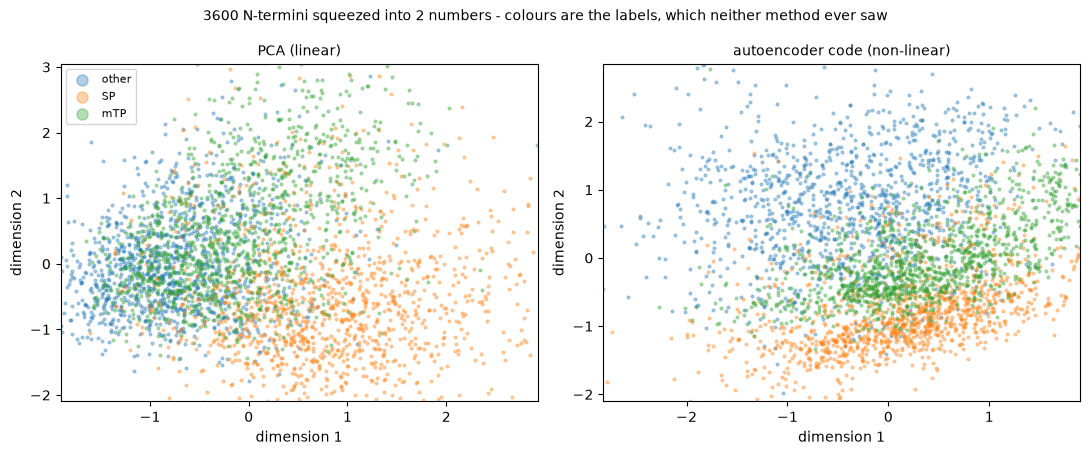

In [ ]:
# @title Support code: the two projections side by side (figure)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=False)
for ax, Z, name in [(axes[0], Z_pca, "PCA (linear)"), (axes[1], Z_ae, "autoencoder code (non-linear)")]:
    Zs = (Z - Z.mean(0)) / Z.std(0)
    for k, lab in enumerate(LABELS):
        sel = y_all == k
        ax.scatter(Zs[sel, 0], Zs[sel, 1], s=4, alpha=0.35, color=colours[lab], label=lab)
    # the autoencoder code has a few far outliers: zoom on the bulk (99% of the points)
    ax.set_xlim(*np.percentile(Zs[:, 0], [0.5, 99.5])); ax.set_ylim(*np.percentile(Zs[:, 1], [0.5, 99.5]))
    ax.set_title(name, fontsize=10); ax.set_xlabel("dimension 1"); ax.set_ylabel("dimension 2")
axes[0].legend(markerscale=4, fontsize=8)
fig.suptitle("3600 N-termini squeezed into 2 numbers - colours are the labels, "
             "which neither method ever saw", fontsize=10)
plt.tight_layout()

In [ ]:
# How much class structure survives in 2 dimensions? Ask a 15-NN classifier (labels used ONLY here).
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

for name, Z in [("PCA", Z_pca), ("autoencoder", Z_ae)]:
    Zs = (Z - Z.mean(0)) / Z.std(0)
    acc5 = cross_val_score(KNeighborsClassifier(15), Zs, y_all, cv=5).mean()
    print(f"{name:12s}: 15-NN 5-fold accuracy on the 2 coordinates = {acc5:.3f}")
print(f"{'chance':12s}: {1/3:.3f}   (for reference, the supervised GRU of class 3 on the 50x20 inputs: 0.944)")

PCA         : 15-NN 5-fold accuracy on the 2 coordinates = 0.650
autoencoder : 15-NN 5-fold accuracy on the 2 coordinates = 0.761
chance      : 0.333   (for reference, the supervised GRU on 50x20 inputs: 0.944)


❓ Compare the two panels and the two numbers. What did the bottleneck buy over PCA?

**Answer.** PCA's two components explain a derisory **1.3%** of the variance of the one-hot matrix -
unsurprising, since a one-hot encoding is almost isotropic: there is no linear direction in which
sequences vary a lot. The autoencoder's reconstruction error is only marginally better (0.0447 vs
0.0451), so as a *compressor* it barely wins. But as a **map** it is clearly better: the 2-D code
supports a 15-NN accuracy of **0.761** against **0.650** for PCA (chance 0.333), and in the figure
the three classes occupy visibly tighter regions, with the SP proteins pushed into a corner of their
own. (The code has a handful of far outliers, so the right panel is zoomed on the central 99%.) A non-linear encoder can bend the 1000-dimensional space so that
"has a hydrophobic run somewhere" becomes a *coordinate*; a linear projection cannot, because that
property is not a linear function of the one-hot matrix.

The headline, though, is that **the labels were never used**. The structure the autoencoder found -
which is largely the SP/non-SP distinction - was simply the dominant structure in the raw sequences.
This is the seed of self-supervised learning: define a task that needs no annotation (here,
reconstruction; for a language model, predicting a masked residue) and the representation you get on
the way is useful for tasks you had not thought of.

❓ And the honest comparison: 0.761 is well below the supervised GRU's 0.944. Two numbers are not 50
residues. Unsupervised representations are cheap but lossy - unless they are very big, which is where
`extra07` picks up.

✏️ **Exercise 1.1.** Not every dataset has structure that composition can see. Take the **enzymes**
table (2047 proteins, EC class 1-6), featurize each *full* sequence by its 20-dimensional amino-acid
composition, and project to 2 dimensions with both PCA and an autoencoder. Score both with the same
15-NN probe, using `ec_class` as the label. Also fit a logistic regression on the full 20 features as
a ceiling. Does the chemistry of the reaction show up in the composition?

{1: 350, 2: 350, 3: 350, 4: 350, 5: 350, 6: 297}    (EC 1=oxidoreductase ... 6=ligase)


PCA         : 15-NN 5-fold accuracy on 2 coordinates = 0.206
autoencoder : 15-NN 5-fold accuracy on 2 coordinates = 0.232
20 features : logistic regression, 5-fold = 0.281
chance      : 0.171  (largest class)


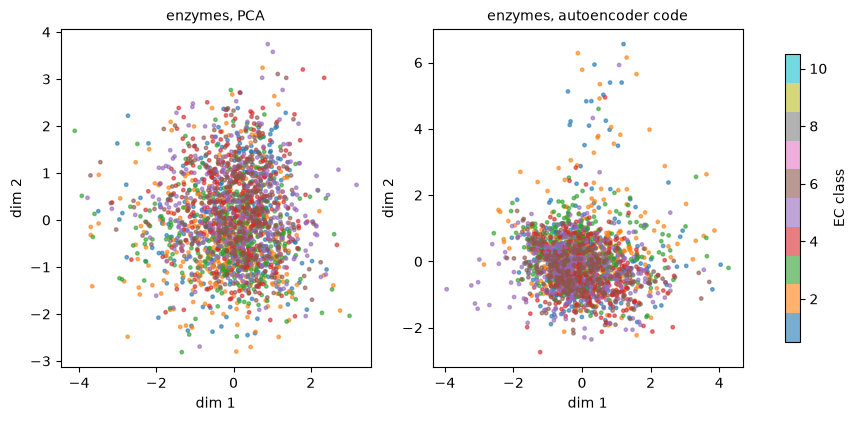

In [ ]:
ez = load_enzymes()
print(ez["ec_class"].value_counts().sort_index().to_dict(), "   (EC 1=oxidoreductase ... 6=ligase)")

X_ez = np.vstack(ez["sequence"].map(aa_composition))
X_ez = (X_ez - X_ez.mean(0)) / X_ez.std(0)               # standardise: PCA and MSE need it here
y_ez = ez["ec_class"].values

pca_ez = PCA(n_components=2, random_state=RNG).fit(X_ez)
Z_pca_ez = pca_ez.transform(X_ez)

torch.manual_seed(RNG)
ae_ez = Autoencoder(d_in=20, hidden=32, code=2)
mse_ez = train_autoencoder(ae_ez, torch.tensor(X_ez, dtype=torch.float32), epochs=60)
with torch.no_grad():
    Z_ae_ez = ae_ez.encoder(torch.tensor(X_ez, dtype=torch.float32)).numpy()

for name, Z in [("PCA", Z_pca_ez), ("autoencoder", Z_ae_ez)]:
    Zs = (Z - Z.mean(0)) / Z.std(0)
    print(f"{name:12s}: 15-NN 5-fold accuracy on 2 coordinates = "
          f"{cross_val_score(KNeighborsClassifier(15), Zs, y_ez, cv=5).mean():.3f}")
print(f"{'20 features':12s}: logistic regression, 5-fold = "
      f"{cross_val_score(LogisticRegression(max_iter=5000), X_ez, y_ez, cv=5).mean():.3f}")
print(f"{'chance':12s}: {(y_ez == 1).mean():.3f}  (largest class)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, Z, name in [(axes[0], Z_pca_ez, "PCA"), (axes[1], Z_ae_ez, "autoencoder code")]:
    Zs = (Z - Z.mean(0)) / Z.std(0)
    sc = ax.scatter(Zs[:, 0], Zs[:, 1], s=6, alpha=0.6, c=y_ez, cmap="tab10", vmin=0.5, vmax=10.5)
    ax.set_title(f"enzymes, {name}", fontsize=10); ax.set_xlabel("dim 1"); ax.set_ylabel("dim 2")
fig.colorbar(sc, ax=axes, label="EC class", shrink=0.85);

**Answer.** No. Both projections are one undifferentiated blob, the autoencoder (0.232) barely beats
PCA (0.206), and even logistic regression on all 20 composition features reaches only **0.281**
against a 0.171 majority-class baseline. Amino-acid composition essentially does not know what
reaction an enzyme catalyses - and it should not: catalytic chemistry lives in the **spatial
arrangement of a handful of residues in the active site**, which survives neither counting nor a
2-D bottleneck.

Compare this with the targeting signals, where the *same* featurization reaches 0.802 (`extra05`,
Part 1): a featurization is not good
or bad in the abstract, only good or bad **for a task**. Targeting signals are a bulk
physico-chemical property of 30 residues, so counting works. Catalysis is not.

This is exactly the gap that `extra07` and `extra06` fill: replace the hand-made 20-vector with a 1280-dimensional
embedding from a protein language model that has read millions of sequences, and EC class becomes
predictable.

## Part 2 - Generating peptides, and judging the result honestly

Slide 54 shows peptide generation with a recurrent network and slides 55-56 molecular generation
through the latent space of a variational autoencoder. The shared recipe: train a network to
reproduce a distribution of sequences, then sample from it and hope the samples are new and good.

We can do the recurrent half in a couple of minutes. The training set is the **1200 signal
peptides** of the targeting dataset (class 3): the N-terminal address labels that send a protein
into the secretory pathway. A signal peptide has a loose but real grammar - a short positively
charged start, a hydrophobic core, a small-residue cleavage site - and no fixed motif, which makes
it a fair target for a generative model.

The network reads the peptide one residue at a time and predicts the next one. That is all. To
generate, you feed it a start token and sample residue by residue from its predicted
distribution.

In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)

tp = load_targeting()
LENGTH = 30                                        # residues we model
signal_peptides = [s[:LENGTH] for s in tp.loc[tp["label"] == "SP", "nterm"]]
print(len(signal_peptides), "signal peptides, e.g.", signal_peptides[0])

aa_index = {a: i for i, a in enumerate(AA)}
START = 20                                         # a 21st token meaning "begin"
tokens = torch.tensor([[START] + [aa_index[a] for a in s] for s in signal_peptides])
print("token tensor:", tuple(tokens.shape))

1200 signal peptides, e.g. MVSSFFMASTLLAISSCFNSSISRAKGYND
token tensor: (1200, 31)


In [ ]:
class PeptideGenerator(nn.Module):
    """Character-level GRU: given the residues so far, score the next residue."""

    def __init__(self, hidden=64):
        super().__init__()
        self.embed = nn.Embedding(21, 16)          # 20 residues + START
        self.gru = nn.GRU(16, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 20)

    def forward(self, x, state=None):
        out, state = self.gru(self.embed(x), state)
        return self.head(out), state


torch.manual_seed(RNG)
generator = PeptideGenerator()
print(sum(p.numel() for p in generator.parameters()), "trainable parameters")

inputs, targets = tokens[:, :-1], tokens[:, 1:]    # predict residue t+1 from residues 1..t
optimiser = torch.optim.Adam(generator.parameters(), lr=0.01)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(1, 41):
    order = torch.randperm(len(inputs))
    total = 0.0
    for start in range(0, len(order), 64):
        batch = order[start:start + 64]
        scores, _ = generator(inputs[batch])
        loss = loss_fn(scores.reshape(-1, 20), targets[batch].reshape(-1))
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        total += loss.item() * len(batch)
    if epoch % 10 == 0:
        print(f"epoch {epoch:3d}  mean loss = {total / len(inputs):.3f}  "
              f"(a uniform guess would give {np.log(20):.3f})")

17380 trainable parameters


epoch  10  mean loss = 2.446  (a uniform guess would give 2.996)


epoch  20  mean loss = 2.354  (a uniform guess would give 2.996)


epoch  30  mean loss = 2.273  (a uniform guess would give 2.996)


epoch  40  mean loss = 2.213  (a uniform guess would give 2.996)


In [ ]:
@torch.no_grad()
def sample_peptides(n=6, temperature=1.0, seed=RNG):
    """Sample n peptides residue by residue from the trained network."""
    rng = torch.Generator().manual_seed(seed)
    x = torch.full((n, 1), START)
    state, drawn = None, []
    for _ in range(LENGTH):
        scores, state = generator(x, state)
        probs = torch.softmax(scores[:, -1] / temperature, dim=-1)
        x = torch.multinomial(probs, 1, generator=rng)
        drawn.append(x)
    return ["".join(AA[i] for i in row) for row in torch.cat(drawn, dim=1).tolist()]


print("generated:")
for s in sample_peptides(6):
    print(" ", s)
print("\nreal, for comparison:")
for s in signal_peptides[:6]:
    print(" ", s)

generated:
  MKNTLIKLFLSSLVFIFSANVNGNLFAKLQ
  MAARFIFLSVIIFTSVIFSLATDAPSGNVF
  MKFHFACAVVLVECVSSGRYIALTNKTNVH
  MAKTILLIPSALSLTETTFSITLDTRAAIT
  MSLSLIMLMAILFFISSQAQLREPEKNNRN
  MARFLPVLTLLVLLIVKEGIRIRVCAKTCL

real, for comparison:
  MVSSFFMASTLLAISSCFNSSISRAKGYND
  MAWTPLLLLLLSHCTGSLSQPVLTQPPSSS
  MAWATLLLPLLNLYTGSVASYELTQLPSVS
  MAWIPLLLPLLTLCTGSEASYELTQPPSVS
  MPLVVAVIFFSLWVFALGQLEQPEISISRP
  MLLLLLLLGPGSGLGAVVSQHPSRVICKSG


They look right: almost all start with methionine, most have a hydrophobic stretch in positions
5-20, several end in a small-residue cleavage-site pattern. **This is where papers stop and where
you should not.** "Looks plausible to me" is not a result. Two cheap checks:

1. does something other than your eye call them signal peptides?
2. is the network inventing, or reciting its training set?

✏️ **Exercise 2.1.** Train a composition-based SP-vs-rest logistic regression on the targeting
data (first 30 residues), and apply it to 200 generated peptides, 200 real signal peptides and 200
`other` N-termini. Then compute, for each generated peptide, its highest percentage identity to
any training peptide, and compare with the same statistic among real signal peptides.

In [ ]:
X_tp = np.vstack([aa_composition(s[:LENGTH]) for s in tp["nterm"]])
is_sp = (tp["label"] == "SP").values
detector_cv = cross_val_score(LogisticRegression(max_iter=2000), X_tp, is_sp, cv=5).mean()
detector = LogisticRegression(max_iter=2000).fit(X_tp, is_sp)
print(f"the SP detector itself is only {detector_cv:.3f} accurate in cross-validation\n")

generated = sample_peptides(200, seed=1)
real_sp = list(np.random.default_rng(RNG).choice(signal_peptides, 200, replace=False))
other = [s[:LENGTH] for s in tp.loc[tp["label"] == "other", "nterm"]][:200]

for label, peptides in [("generated", generated), ("real SP", real_sp), ("real 'other'", other)]:
    called = detector.predict(np.vstack([aa_composition(s) for s in peptides])).mean()
    print(f"{label:14s}: {called:.1%} called 'signal peptide'")

def max_identity(peptide, pool):
    return max(sum(a == b for a, b in zip(peptide, other_pep)) / LENGTH
               for other_pep in pool if other_pep != peptide)

print(f"\nhighest identity to a training peptide:")
print(f"  generated      : {np.mean([max_identity(s, signal_peptides) for s in generated[:50]]):.3f}")
print(f"  real SP vs rest: {np.mean([max_identity(s, signal_peptides) for s in real_sp[:50]]):.3f}")

the SP detector itself is only 0.880 accurate in cross-validation

generated     : 73.0% called 'signal peptide'
real SP       : 81.5% called 'signal peptide'
real 'other'  : 3.5% called 'signal peptide'

highest identity to a training peptide:
  generated      : 0.323


  real SP vs rest: 0.378

❓ Has the network learned to write signal peptides?

**Answer.** It has learned *something*, and the honest statement of what is narrower than the
samples suggest.

What we can claim: the detector calls **73%** of the generated peptides signal peptides, against
**81.5%** of real ones and **3.5%** of real `other` N-termini. The generated peptides land near
the real distribution and nowhere near the negative one. And they are not memorised: a generated
peptide shares on average **0.323** of its residues with its closest training peptide, slightly
*less* than one real signal peptide shares with the next-closest real one (**0.378**). The model
interpolates the grammar rather than reciting examples.

What we cannot claim: the judge is a 30-residue composition model whose own cross-validated
accuracy is **0.880**, and it ignores the order of residues entirely - the one thing a signal
peptide depends on. Passing it is a necessary condition, not evidence of function. A real
assessment needs SignalP or a structural check, and ultimately an experiment: express the fusion
and see whether the protein is secreted. Nothing here tells you whether a single one of these
peptides would work in a cell.

This gap - between a generative model that produces things *shaped* like the training data and a
claim that they *work* - is the main thing to carry away from slides 54-56. The VAE latent space
is prettier and the same caution applies: the decoder will happily hand you a molecule that is
unsynthesisable, unstable, or merely a copy of something in the training set with one atom moved.
Generation is cheap; the filter and the assay are the expensive parts, and they are where the
science is.

## Summary

* An **autoencoder** is trained to reproduce its own input through a bottleneck, with no labels at
  all. On the targeting N-termini its 2-D code separates the three classes better than PCA (15-NN
  0.761 against 0.650, chance 0.333), although as a *compressor* it barely wins. The structure it
  found - largely SP against the rest - is simply the dominant structure of the raw sequences.
* The same trick on enzyme **composition** finds nothing (0.232 against 0.206 for PCA): an
  unsupervised map can only show structure that the featurization contains in the first place.
* This is the seed of self-supervised learning: define a task that needs no annotation, and the
  representation you get on the way is useful for tasks you had not thought of. Pushed to the scale
  of a transformer, it becomes the pretrained embedding of `extra07` and `extra06`.
* A 17k-parameter **GRU** trained to predict the next residue writes peptides that a weak detector
  accepts at nearly the rate of real signal peptides (73% against 81.5%), and that are not copies
  of the training set. That is a **distributional** claim, not a functional one: generation is
  cheap, the filter and the assay are where the science is.

## References and data sources

* Hinton GE, Salakhutdinov RR (2006). Reducing the dimensionality of data with neural networks.
  *Science* 313:504-507. [doi:10.1126/science.1127647](https://doi.org/10.1126/science.1127647)
  — the autoencoder bottleneck as dimensionality reduction.
* Müller AT, Hiss JA, Schneider G (2018). Recurrent neural network model for constructive peptide
  design. *J. Chem. Inf. Model.* 58:472-479.
  [doi:10.1021/acs.jcim.7b00414](https://doi.org/10.1021/acs.jcim.7b00414) — peptide generation
  with an RNN (slide 54).
* Gómez-Bombarelli R, Wei JN, Duvenaud D, et al. (2018). Automatic chemical design using a
  data-driven continuous representation of molecules. *ACS Central Science* 4:268-276.
  [doi:10.1021/acscentsci.7b00572](https://doi.org/10.1021/acscentsci.7b00572) — the molecular VAE
  and its latent space (slides 55-56).
* Teufel F, Almagro Armenteros JJ, Johansen AR, et al. (2022). SignalP 6.0 predicts all five types
  of signal peptides using protein language models. *Nature Biotechnology* 40:1023-1025.
  [doi:10.1038/s41587-021-01156-3](https://doi.org/10.1038/s41587-021-01156-3) — what a real judge
  of Part 2 would look like.
* `data/targeting.tsv`, `data/enzymes.tsv`: reviewed entries of UniProtKB/Swiss-Prot; see
  `README.md` and `data_prep/`.
* Slides: `slides/ai-qbio-unimi_2026_r1.pdf`, p. 34 (autoencoders) and pp. 54-56 (generative models).